In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"D:\Sasi\GUVI HCL AI-ML\EV_Charging Project\data\cleaned\CleanedChargingRecords.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72296 entries, 0 to 72295
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   UserID          72296 non-null  int64  
 1   ChargerID       72296 non-null  int64  
 2   ChargerCompany  72296 non-null  int64  
 3   Location        72296 non-null  object 
 4   ChargerType     72296 non-null  int64  
 5   StartDatetime   72296 non-null  object 
 6   EndDatetime     72296 non-null  object 
 7   Duration        72296 non-null  int64  
 8   Demand          72296 non-null  float64
dtypes: float64(1), int64(5), object(3)
memory usage: 5.0+ MB


In [3]:
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])
df['EndDatetime'] = pd.to_datetime(df['EndDatetime'])

C:\Users\ssasi\AppData\Local\Temp\ipykernel_24912\3632452289.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])
C:\Users\ssasi\AppData\Local\Temp\ipykernel_24912\3632452289.py:2: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['EndDatetime'] = pd.to_datetime(df['EndDatetime'])


In [23]:
df.dtypes

UserID                     int64
ChargerID                  int64
ChargerCompany             int64
Location                     str
ChargerType                int64
StartDatetime     datetime64[us]
EndDatetime       datetime64[us]
Duration                   int64
Demand                   float64
dtype: object

In [20]:
print('--- Demand (kWh) Statistics ---')
df['Demand'].describe()

--- Demand (kWh) Statistics ---


count    72296.000000
mean        17.562084
std         13.460918
min          0.010000
25%          7.680000
50%         14.250000
75%         23.200000
max         97.000000
Name: Demand, dtype: float64

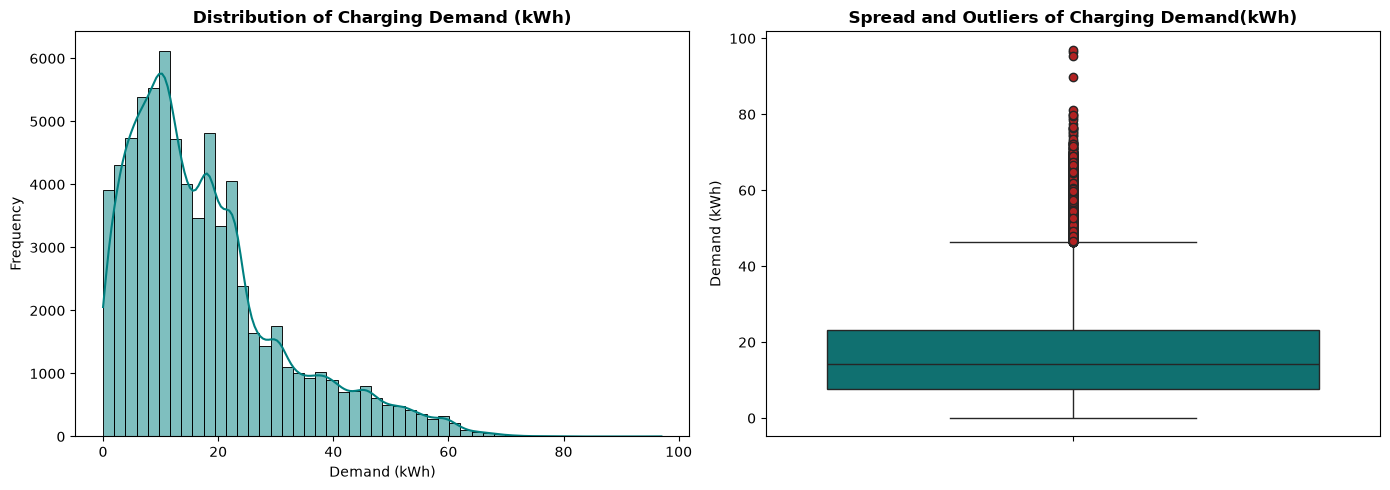

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Demand'], kde=True, ax=axes[0], color='teal', bins=50)
axes[0].set_title('Distribution of Charging Demand (kWh)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Demand (kWh)')
axes[0].set_ylabel('Frequency')
sns.boxplot(df['Demand'],ax=axes[1],color='teal',flierprops={'markerfacecolor':'firebrick'})
axes[1].set_title('Spread and Outliers of Charging Demand(kWh)',fontsize=12,fontweight='bold')
axes[1].set_ylabel('Demand (kWh)')
plt.tight_layout()
plt.show()

In [21]:
print('\n--- Duration (Minutes) Statistics ---')
print(df['Duration'].describe())


--- Duration (Minutes) Statistics ---
count    72296.000000
mean       156.675321
std        159.196947
min          1.000000
25%         41.000000
50%        115.000000
75%        205.000000
max       4717.000000
Name: Duration, dtype: float64


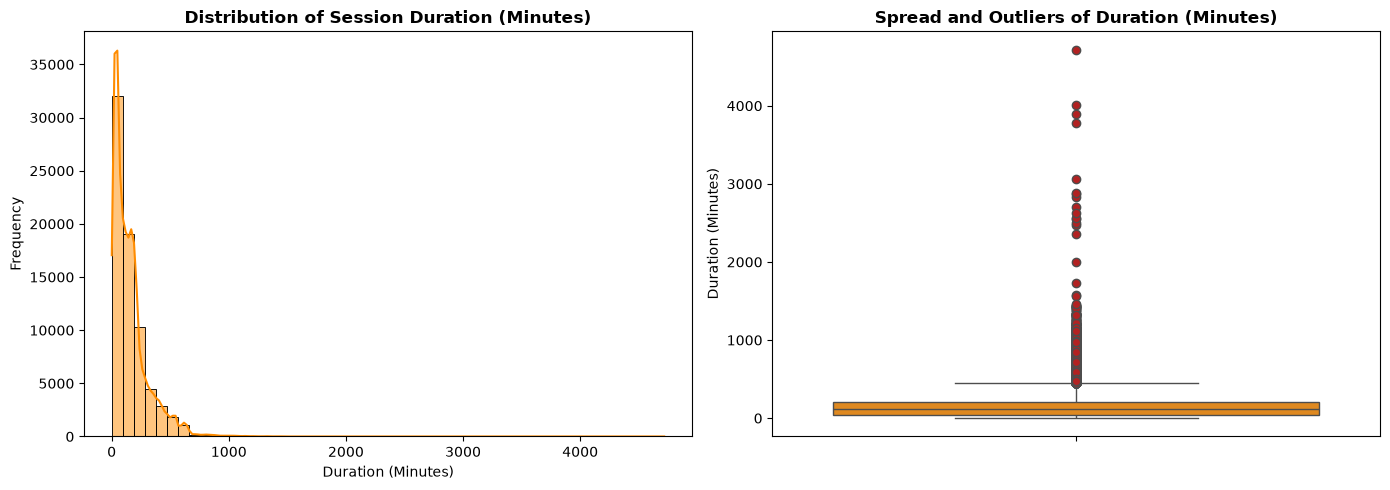

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Duration'], kde=True, ax=axes[0], color='darkorange', bins=50)
axes[0].set_title('Distribution of Session Duration (Minutes)',fontsize=12,fontweight='bold',)
axes[0].set_xlabel('Duration (Minutes)')
axes[0].set_ylabel('Frequency')
sns.boxplot(df['Duration'],ax=axes[1],color='darkorange',flierprops={'markerfacecolor':'firebrick'})
axes[1].set_title('Spread and Outliers of Duration (Minutes)',fontsize=12,fontweight='bold')
axes[1].set_ylabel('Duration (Minutes)')
plt.tight_layout()
plt.show()

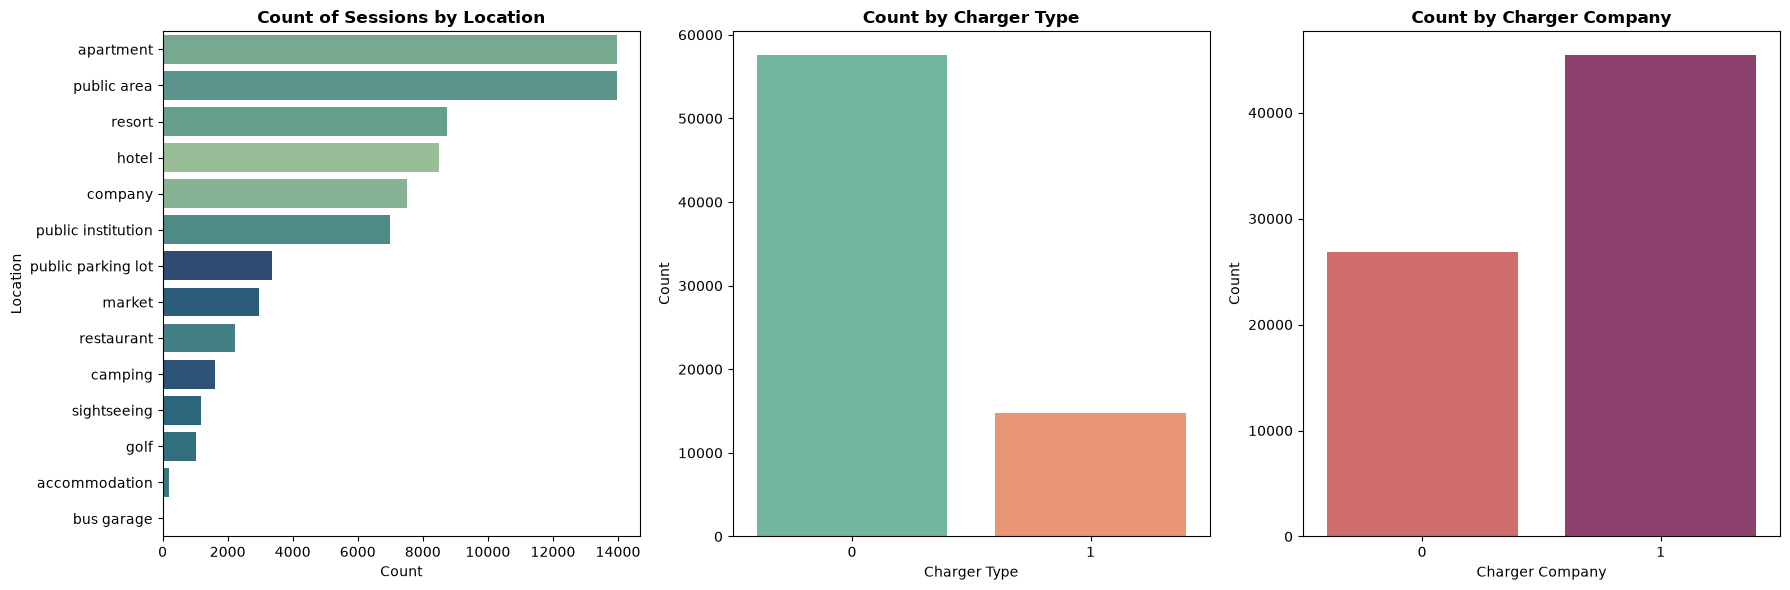

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Location countplot
loc_order = df['Location'].value_counts().index
sns.countplot(data=df, y='Location', order=loc_order, ax=axes[0],hue='Location', palette='crest',legend=False)
axes[0].set_title('Count of Sessions by Location', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Location')

# 2. ChargerType countplot
sns.countplot(data=df, x='ChargerType', ax=axes[1],hue='ChargerType', palette='Set2',legend=False)
axes[1].set_title('Count by Charger Type', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Charger Type')
axes[1].set_ylabel('Count')

# 3. ChargerCompany countplot
sns.countplot(data=df, x='ChargerCompany', ax=axes[2],hue='ChargerCompany', palette='flare',legend=False)
axes[2].set_title('Count by Charger Company', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Charger Company')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [5]:
df['Start_Hour'] = df['StartDatetime'].dt.hour
df['Start_DayOfWeek'] = df['StartDatetime'].dt.dayofweek
df['Start_Month'] = df['StartDatetime'].dt.month
df['Is_Weekend'] = df['Start_DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

def get_time_of_day(hour):
  if 5 <= hour < 12:
    return 'Morning'
  elif 12 <= hour < 17:
    return 'Afternoon'
  elif 17 <= hour < 22:
    return 'Evening'
  else:
    return 'Night'
df['TimeOfDay'] = df['Start_Hour'].apply(get_time_of_day)
df['Is_Peak_Hour'] = df['Start_Hour'].apply(lambda x: 1 if 17 <= x <= 22 else 0)

df.to_csv(r"D:\Sasi\GUVI HCL AI-ML\EV_Charging Project\data\cleaned\FEChargingRecords.csv", index=False)
print('Feature engineering completed. Shape:', df.shape)

Feature engineering completed. Shape: (72296, 15)


In [26]:
loc_demand = (df.groupby('Location')['Demand'].mean().sort_values(ascending=False).reset_index())
loc_demand

,Location,Demand
0,accommodation,29.211774
1,bus garage,28.587586
2,camping,25.682648
3,apartment,18.826545
4,public area,18.042143
5,restaurant,17.869309
6,public institution,17.511281
7,resort,17.464532
8,public parking lot,17.324844
9,golf,16.767076


C:\Users\ssasi\AppData\Local\Temp\ipykernel_16048\3768691980.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=loc_demand,x='Demand',y='Location',palette='viridis',errorbar=None)


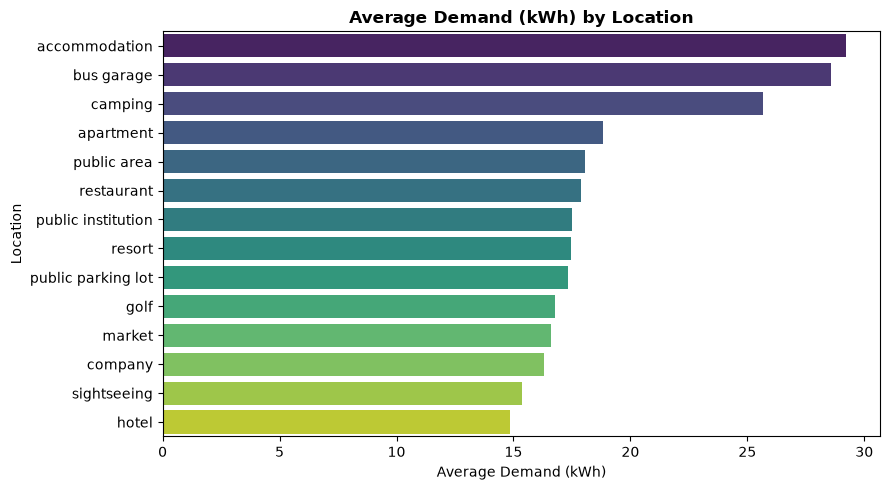

In [40]:
plt.figure(figsize=(9,5))
sns.barplot(data=loc_demand,x='Demand',y='Location',palette='viridis',errorbar=None)
plt.title('Average Demand (kWh) by Location', fontsize=12, fontweight='bold')
plt.xlabel('Average Demand (kWh)')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

In [8]:
loc_duration = (df.groupby('Location')['Duration'].mean().sort_values(ascending=False).reset_index())
loc_duration

,Location,Duration
0,accommodation,269.451613
1,camping,245.272840
2,apartment,219.362010
3,resort,179.139936
4,golf,163.681287
5,restaurant,158.842438
6,hotel,153.027895
7,company,152.349230
8,public area,135.411086
9,public institution,121.728576


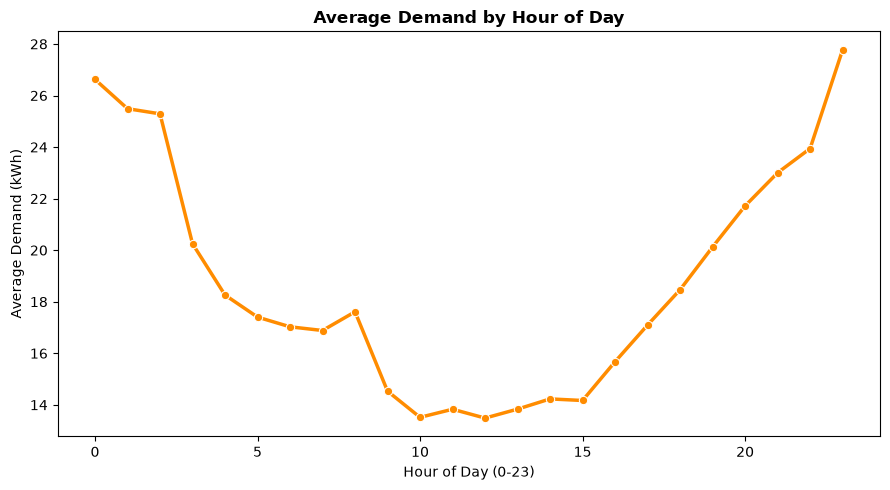

In [43]:
hourly_demand = df.groupby('Start_Hour')['Demand'].mean().reset_index()
plt.figure(figsize=(9,5))
sns.lineplot(data=hourly_demand,x='Start_Hour',y='Demand',marker='o',color='darkorange',linewidth=2.5,)
plt.title('Average Demand by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Average Demand (kWh)')
plt.tight_layout()
plt.show()

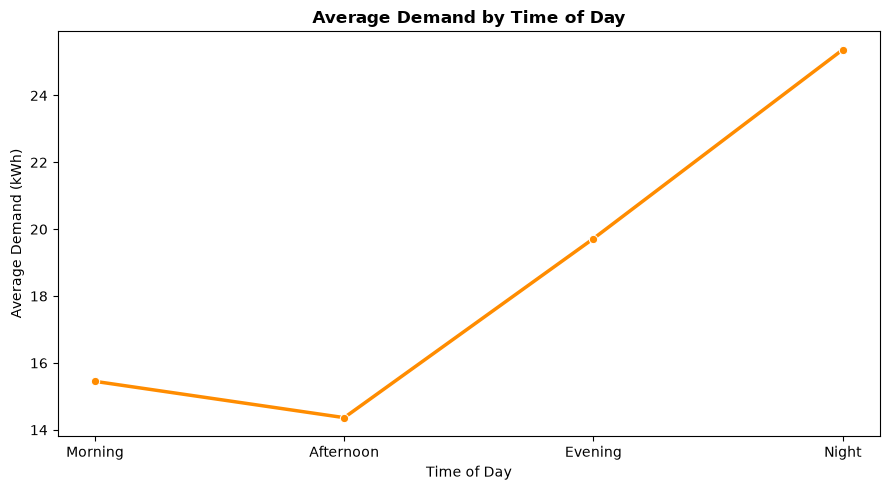

In [45]:
time_order = ['Morning','Afternoon','Evening','Night']
df['TimeOfDay'] = pd.Categorical(df['TimeOfDay'],categories=time_order,ordered=True)
time_demand = df.groupby('TimeOfDay')['Demand'].mean().reset_index()
plt.figure(figsize=(9,5))
sns.lineplot(data=time_demand,x='TimeOfDay',y='Demand',marker='o',color='darkorange',linewidth=2.5,)
plt.title('Average Demand by Time of Day', fontsize=12, fontweight='bold')
plt.xlabel('Time of Day')
plt.ylabel('Average Demand (kWh)')
plt.tight_layout()
plt.show()

C:\Users\ssasi\AppData\Local\Temp\ipykernel_20588\1612406416.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=daywise_demand,x='Start_DayOfWeek',y='Demand',palette='crest')


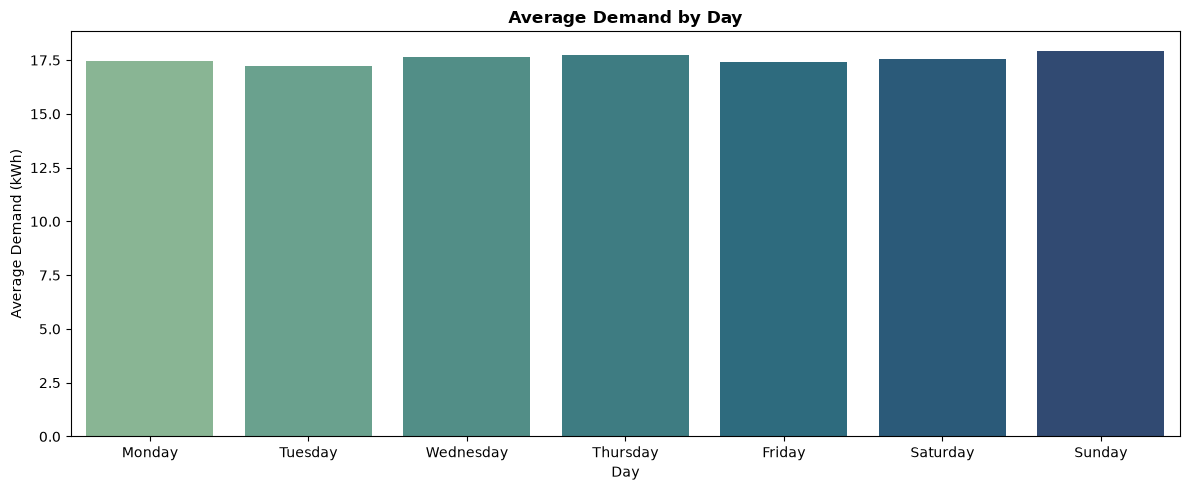

,Start_DayOfWeek,Demand
0,Monday,17.445014
1,Tuesday,17.210313
2,Wednesday,17.652314
3,Thursday,17.753396
4,Friday,17.433668
5,Saturday,17.549289
6,Sunday,17.940854


In [15]:
daywise_demand = df.groupby('Start_DayOfWeek')['Demand'].mean().reset_index()
day_map = {0:'Monday',1:'Tuesday',2:'Wednesday',3:'Thursday',4:'Friday',5:'Saturday',6:'Sunday'}
daywise_demand['Start_DayOfWeek'] = daywise_demand['Start_DayOfWeek'].map(day_map)
plt.figure(figsize=(12,5))
sns.barplot(data=daywise_demand,x='Start_DayOfWeek',y='Demand',palette='crest')
plt.title('Average Demand by Day', fontsize=12, fontweight='bold')
plt.xlabel('Day')
plt.ylabel('Average Demand (kWh)')
plt.tight_layout()
plt.show()
daywise_demand

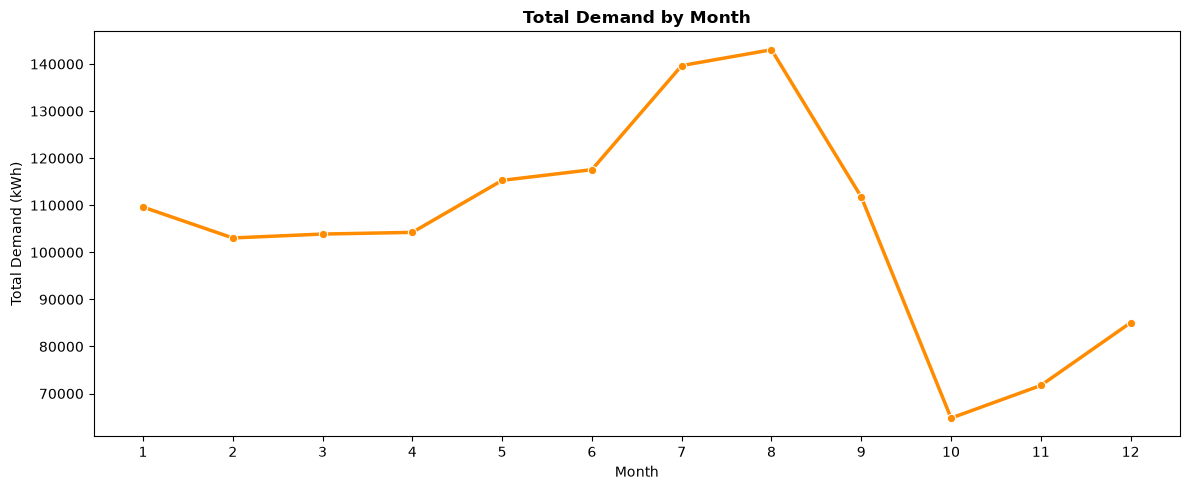

,Start_Month,Demand
0,1,109615.51
1,2,103053.45
2,3,103879.63
3,4,104240.21
4,5,115281.81
5,6,117561.20
6,7,139668.53
7,8,143029.80
8,9,111770.32
9,10,64790.90


In [17]:
monthly_demand = df.groupby('Start_Month')['Demand'].sum().reset_index()
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly_demand,x='Start_Month',y='Demand',marker='o',color='darkorange',linewidth=2.5)
plt.title('Total Demand by Month', fontsize=12, fontweight='bold')
plt.xlabel('Month')
plt.xticks(range(1,13))
plt.ylabel('Total Demand (kWh)')
plt.tight_layout()
plt.show()
monthly_demand

In [7]:
df.groupby('ChargerType')['Demand'].agg(('mean','count','sum')).reset_index()

,ChargerType,mean,count,sum
0,0,17.149918,57540,986806.31
1,1,19.169295,14756,282862.11


In [8]:
df.groupby('ChargerCompany')['Demand'].agg(('mean','count','sum')).reset_index()

,ChargerCompany,mean,count,sum
0,0,16.820956,26893,452365.98
1,1,18.001067,45403,817302.44


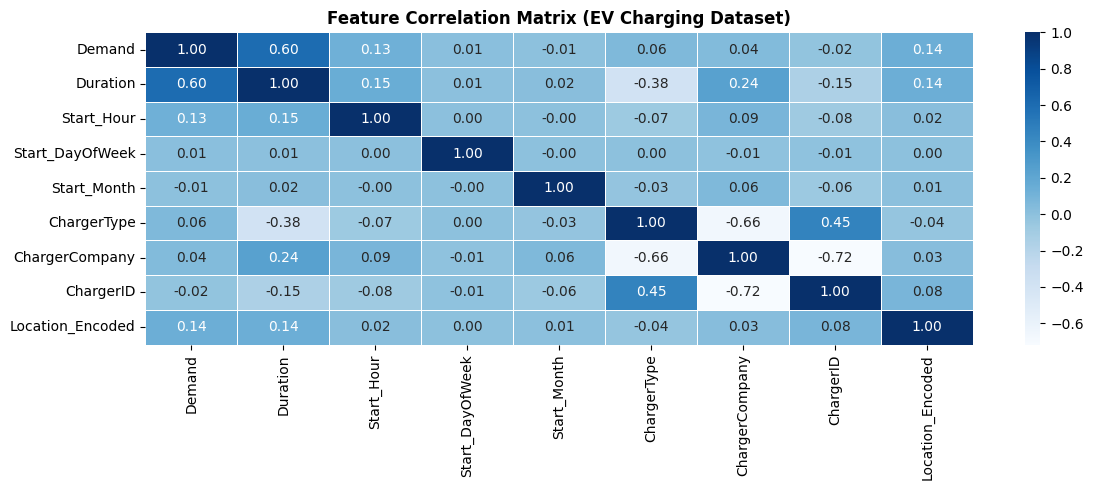

In [11]:
location_means = df['Demand'].groupby(df['Location']).mean().to_dict()
global_mean = df['Demand'].mean()

df['Location_Encoded'] = (df['Location'].map(location_means).fillna(global_mean))
numeric_cols = ['Demand','Duration','Start_Hour','Start_DayOfWeek','Start_Month','ChargerType','ChargerCompany','ChargerID','Location_Encoded']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 5))
sns.heatmap(corr_matrix,annot=True,fmt='.2f',cmap='Blues',cbar=True,linewidths=0.5,)
plt.title('Feature Correlation Matrix (EV Charging Dataset)',fontsize=12,fontweight='bold',)
plt.tight_layout()
plt.show()

In [12]:
user_history = (df.groupby('UserID')['Demand'].agg(User_Mean_Demand='mean',User_Session_Count='count',User_Total_Demand='sum',).reset_index())
user_history

,UserID,User_Mean_Demand,User_Session_Count,User_Total_Demand
0,0,16.755584,31296,524382.75
1,1,35.895413,109,3912.60
2,2,20.174000,40,806.96
3,3,22.888000,35,801.08
4,4,15.978588,170,2716.36
...,...,...,...,...
2330,2497,19.200000,2,38.40
2331,2498,15.400000,2,30.80
2332,2499,4.600000,1,4.60
2333,2500,2.560000,1,2.56


In [13]:
charger_history = df.groupby('ChargerID')['Demand'].agg(Charger_Mean_Demand='mean',Charger_Session_Count='count',Charger_Total_Demand='sum',).reset_index()
charger_history

,ChargerID,Charger_Mean_Demand,Charger_Session_Count,Charger_Total_Demand
0,1,14.805524,391,5788.96
1,2,18.392222,63,1158.71
2,3,14.027596,549,7701.15
3,5,23.444204,402,9424.57
4,7,11.646552,29,337.75
...,...,...,...,...
2111,2630,12.300000,1,12.30
2112,2647,11.140000,2,22.28
2113,2649,0.500000,1,0.50
2114,2670,14.365000,2,28.73
